<a href="https://colab.research.google.com/github/theatu824/MSSP607-GitHub/blob/main/Assignments/theatu824_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os

github_token = userdata.get('Git_Key')
owner = 'theatu824' # Replace with the GitHub repository owner
repository = 'MSSP607-Github' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607-Github


In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt

In [3]:
sales = pd.read_csv("data/InternetSales.csv",encoding='latin-1')
sales.head()

/tmp/ipykernel_1021/2703068425.py:1: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv("data/InternetSales.csv",encoding='latin-1')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [4]:
sales.describe()

,ID,CustomerKey,GeographyKey,YearlyIncome,TotalChildren,NumberChildrenAtHome,HouseOwnerFlag,NumberCarsOwned,ProductKey,OrderDateKey,...,ExtendedAmount,UnitPriceDiscountPct,DiscountAmount,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber
count,60398.000000,60398.000000,60398.000000,60398.000000,60398.00000,60398.000000,60398.000000,60398.000000,60398.000000,6.039800e+04,...,60398.000000,60398.0,60398.0,60398.000000,60398.000000,60398.000000,60398.000000,60398.000000,0.0,0.0
mean,30198.500000,18841.685420,230.516292,59715.056790,1.85074,1.080317,0.690404,1.509189,437.557932,2.012973e+07,...,486.086911,0.0,0.0,286.065657,286.065657,486.086911,38.886954,12.152217,NaN,NaN
std,17435.545116,5432.430404,192.403184,33065.426837,1.62107,1.585964,0.462331,1.154163,118.088390,4.745050e+03,...,928.489892,0.0,0.0,552.457641,552.457641,928.489892,74.279193,23.212248,NaN,NaN
min,0.000000,11000.000000,2.000000,10000.000000,0.00000,0.000000,0.000000,0.000000,214.000000,2.010123e+07,...,2.290000,0.0,0.0,0.856500,0.856500,2.290000,0.183200,0.057300,NaN,NaN
25%,15099.250000,14003.000000,51.000000,30000.000000,0.00000,0.000000,0.000000,1.000000,359.000000,2.013040e+07,...,7.950000,0.0,0.0,2.973300,2.973300,7.950000,0.636000,0.198800,NaN,NaN
50%,30198.500000,18143.000000,211.000000,60000.000000,2.00000,0.000000,1.000000,2.000000,479.000000,2.013071e+07,...,29.990000,0.0,0.0,11.216300,11.216300,29.990000,2.399200,0.749800,NaN,NaN
75%,45297.750000,23429.750000,329.000000,80000.000000,3.00000,2.000000,1.000000,2.000000,529.000000,2.013102e+07,...,539.990000,0.0,0.0,294.579700,294.579700,539.990000,43.199200,13.499800,NaN,NaN
max,60397.000000,29483.000000,654.000000,170000.000000,5.00000,5.000000,1.000000,4.000000,606.000000,2.014013e+07,...,3578.270000,0.0,0.0,2171.294200,2171.294200,3578.270000,286.261600,89.456800,NaN,NaN


In [5]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 60 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        60398 non-null  int64  
 1   CustomerKey               60398 non-null  int64  
 2   GeographyKey              60398 non-null  int64  
 3   City                      60398 non-null  object 
 4   CountryRegionCode         60398 non-null  object 
 5   EnglishCountryRegionName  60398 non-null  object 
 6   CustomerAlternateKey      60398 non-null  object 
 7   Title                     307 non-null    object 
 8   FirstName                 60398 non-null  object 
 9   MiddleName                34903 non-null  object 
 10  LastName                  60398 non-null  object 
 11  NameStyle                 60398 non-null  bool   
 12  BirthDate                 60398 non-null  object 
 13  MaritalStatus             60398 non-null  object 
 14  Suffix

In [6]:
#Date Conversion
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'],errors = 'raise')
display(sales['OrderDate'].dtype)
#Extract order year
sales['OrderYear'] = sales['OrderDate'].dt.year

dtype('<M8[ns]')

In [7]:
# Check categorical values and record counts.
display(sales['Gender'].value_counts(dropna=False))
display(sales['HouseOwnerFlag'].value_counts(dropna=False))
display(sales['EnglishCountryRegionName'].value_counts(dropna=False))

,count
Gender,
M,30381
F,30017


,count
HouseOwnerFlag,
1,41699
0,18699


,count
EnglishCountryRegionName,
United States,21344
Australia,13345
Canada,7620
United Kingdom,6906
Germany,5625
France,5558


In [8]:
# Check the first and last observed order dates in each year.
sales.groupby('OrderYear')['OrderDate'].agg(['min', 'max'])

,min,max
OrderYear,,
2010,2010-12-29,2010-12-31
2011,2011-01-01,2011-12-31
2012,2012-01-01,2012-12-31
2013,2013-01-01,2013-12-31
2014,2014-01-01,2014-01-28


In [9]:
# Count duplicate order-line keys beyond the first occurrence.
sales.duplicated(subset=['SalesOrderNumber', 'SalesOrderLineNumber']).sum()

#Each combination of SalesOrderNumber and SalesOrderLineNumber is unique. No duplicate order-line keys were found.

np.int64(0)

In [10]:
# Check the consistency of customer attributes across sales records.
customer_checks = sales.groupby('CustomerKey')[['YearlyIncome', 'Gender', 'HouseOwnerFlag', 'EnglishCountryRegionName']].nunique()
display((customer_checks > 1).sum())
display((sales['CustomerKey'] != sales['CustomerKey.1']).sum())

,0
YearlyIncome,0
Gender,0
HouseOwnerFlag,0
EnglishCountryRegionName,0


np.int64(0)

In [11]:
# Check the relationship between product keys and product names.
names_per_key = sales.groupby('ProductKey')['EnglishProductName'].nunique()
keys_per_name = sales.groupby('EnglishProductName')['ProductKey'].nunique()

print("PRODUCT MAPPING CHECKS")
print("Product keys with multiple names:", (names_per_key > 1).sum())
print("Product names with multiple keys:", (keys_per_name > 1).sum())

PRODUCT MAPPING CHECKS
Product keys with multiple names: 0
Product names with multiple keys: 28


In [12]:
# Summarize key numeric variables.
numeric_columns = [
    'YearlyIncome', 'OrderQuantity', 'UnitPrice',
    'SalesAmount', 'ExtendedAmount', 'TotalProductCost'
]

print("\nNUMERIC SUMMARY")
numeric_summary = sales[numeric_columns].describe().T
display(numeric_summary.style.format('{:,.2f}'))


NUMERIC SUMMARY


,count,mean,std,min,25%,50%,75%,max
YearlyIncome,"60,398.00","59,715.06","33,065.43","10,000.00","30,000.00","60,000.00","80,000.00","170,000.00"
OrderQuantity,"60,398.00",1.00,0.00,1.00,1.00,1.00,1.00,1.00
UnitPrice,"60,398.00",486.09,928.49,2.29,7.95,29.99,539.99,"3,578.27"
SalesAmount,"60,398.00",486.09,928.49,2.29,7.95,29.99,539.99,"3,578.27"
ExtendedAmount,"60,398.00",486.09,928.49,2.29,7.95,29.99,539.99,"3,578.27"
TotalProductCost,"60,398.00",286.07,552.46,0.86,2.97,11.22,294.58,"2,171.29"


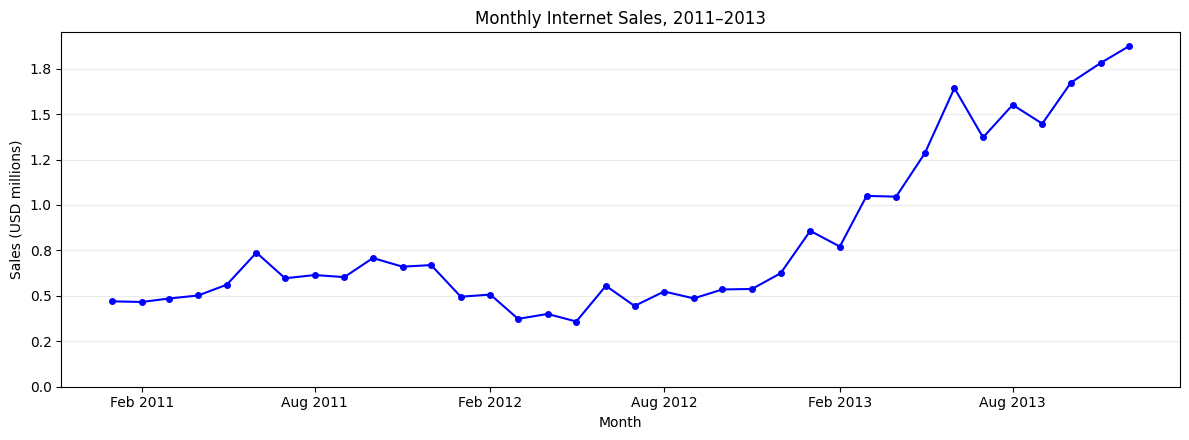

In [37]:
#Monthly Internet Sales Trend
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter

# Summarize monthly Internet sales for complete calendar years.
monthly_sales = (
    sales.loc[sales['OrderDate'].between('2011-01-01', '2013-12-31')]
    .set_index('OrderDate')['SalesAmount']
    .resample('MS').sum()
)

# Plot monthly sales in millions.
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(
    monthly_sales.index, monthly_sales / 1_000_000,
    color='blue', marker='o', markersize=4, linewidth=1.5
)

ax.set(
    title='Monthly Internet Sales, 2011–2013',
    xlabel='Month',
    ylabel='Sales (USD millions)'
)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.1f}'))
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.25)

fig.tight_layout()
fig.savefig('monthly_internet_sales.png', dpi=300, bbox_inches='tight')
plt.show()

1. What are the Internet sales of Adventure Works by year for each Country Region?

In [13]:
yearly_country_sales = sales.groupby(['OrderYear','EnglishCountryRegionName'])['SalesAmount'].sum().reset_index()
annual_sales_table = yearly_country_sales.pivot(index='OrderYear',columns='EnglishCountryRegionName',values='SalesAmount')
display(annual_sales_table.style.format('{:,.2f}'))

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
OrderYear,,,,,,
2010,"20,909.78","3,578.27","3,399.99",nan,699.10,"14,833.90"
2011,"2,563,732.25","571,571.80","410,845.33","520,500.16","550,591.22","2,458,285.17"
2012,"2,128,407.46","307,604.52","648,065.54","608,657.98","712,700.96","1,437,048.73"
2013,"4,339,443.38","1,085,632.65","1,578,511.80","1,761,876.36","2,124,007.29","5,462,078.86"
2014,"8,507.72","9,457.62","3,195.06","3,277.83","3,713.64","17,542.85"


In [14]:
# Check whether Germany has any sales records in 2010.
germany_2010 = sales.loc[
    (sales['OrderYear'] == 2010)
    & (sales['EnglishCountryRegionName'] == 'Germany')
]

print("Number of records:", len(germany_2010))

Number of records: 0


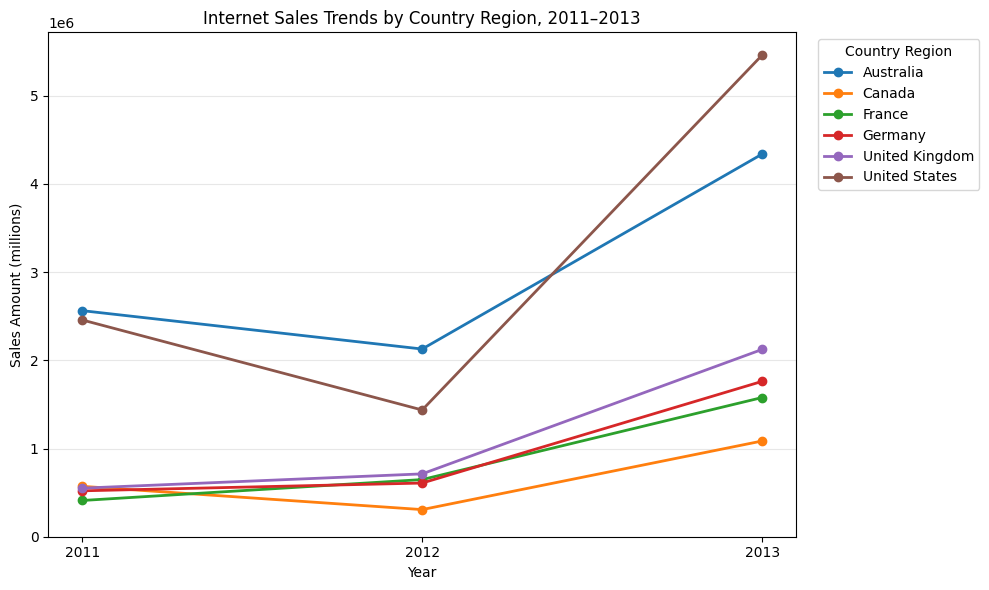

In [15]:
# Select 2011–2013 for comparable annual sales visualization.
plot_sales = annual_sales_table.loc[2011:2013].copy()
# Plot one line for each country region.
ax = plot_sales.plot(kind='line',marker='o',figsize=(10, 6),linewidth=2)
ax.set_title('Internet Sales Trends by Country Region, 2011–2013')
ax.set_xlabel('Year')
ax.set_ylabel('Sales Amount (millions)')
ax.set_xticks([2011, 2012, 2013])
ax.set_ylim(bottom=0)
ax.legend(title='Country Region', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('internet_sales_trends.png', dpi=300, bbox_inches='tight')
plt.show()

2. Generate summary statistics including min, max, and standard deviation for Yearly Income, Gender by Country Regions.  

In [16]:
# Create a customer-level dataset for income analysis.
customers = sales[
    ['CustomerKey', 'EnglishCountryRegionName', 'Gender', 'YearlyIncome']
].drop_duplicates(subset='CustomerKey')

# Summarize customer income by country region and gender.
income_summary = (
    customers.groupby(['EnglishCountryRegionName', 'Gender'])['YearlyIncome']
    .agg(['count', 'mean', 'min', 'max', 'std'])
)

display(income_summary.style.format({
        'count': '{:,.0f}',
        'mean': '{:,.2f}',
        'min': '{:,.2f}',
        'max': '{:,.2f}',
        'std': '{:,.2f}'
    })
)

3. What is the average price of the product category that generates the most sales?

In [17]:
# Inspect unique product names before defining categories.
product_names = sorted(sales['EnglishProductName'].dropna().unique())
print(f"Number of unique product names: {len(product_names)}")
for name in product_names:
    print(name)

Number of unique product names: 130
AWC Logo Cap
All-Purpose Bike Stand
Bike Wash - Dissolver
Classic Vest, L
Classic Vest, M
Classic Vest, S
Fender Set - Mountain
HL Mountain Tire
HL Road Tire
Half-Finger Gloves, L
Half-Finger Gloves, M
Half-Finger Gloves, S
Hitch Rack - 4-Bike
Hydration Pack - 70 oz.
LL Mountain Tire
LL Road Tire
Long-Sleeve Logo Jersey, L
Long-Sleeve Logo Jersey, M
Long-Sleeve Logo Jersey, S
Long-Sleeve Logo Jersey, XL
ML Mountain Tire
ML Road Tire
Mountain Bottle Cage
Mountain Tire Tube
Mountain-100 Black, 38
Mountain-100 Black, 42
Mountain-100 Black, 44
Mountain-100 Black, 48
Mountain-100 Silver, 38
Mountain-100 Silver, 42
Mountain-100 Silver, 44
Mountain-100 Silver, 48
Mountain-200 Black, 38
Mountain-200 Black, 42
Mountain-200 Black, 46
Mountain-200 Silver, 38
Mountain-200 Silver, 42
Mountain-200 Silver, 46
Mountain-400-W Silver, 38
Mountain-400-W Silver, 40
Mountain-400-W Silver, 42
Mountain-400-W Silver, 46
Mountain-500 Black, 40
Mountain-500 Black, 42
Mountain

In [18]:
# Define product subcategories using explicit name prefixes.
subcategory_rules = [
    ('Mountain-', 'Bikes', 'Mountain Bikes'),
    ('Road-', 'Bikes', 'Road Bikes'),
    ('Touring-', 'Bikes', 'Touring Bikes'),
    ('AWC Logo Cap', 'Clothing', 'Caps'),
    ('Classic Vest,', 'Clothing', 'Vests'),
    ('Half-Finger Gloves,', 'Clothing', 'Gloves'),
    ('Long-Sleeve Logo Jersey,', 'Clothing', 'Jerseys'),
    ('Short-Sleeve Classic Jersey,', 'Clothing', 'Jerseys'),
    ('Racing Socks,', 'Clothing', 'Socks'),
    ("Women's Mountain Shorts,", 'Clothing', 'Shorts'),
    ('Sport-100 Helmet,', 'Accessories', 'Helmets')
]

# Define exact matches for the remaining accessories.
accessory_subcategories = {
    'All-Purpose Bike Stand': 'Bike Stands',
    'Bike Wash - Dissolver': 'Maintenance and Repair',
    'Fender Set - Mountain': 'Fenders',
    'HL Mountain Tire': 'Tires',
    'HL Road Tire': 'Tires',
    'Hitch Rack - 4-Bike': 'Bike Racks',
    'Hydration Pack - 70 oz.': 'Hydration Packs',
    'LL Mountain Tire': 'Tires',
    'LL Road Tire': 'Tires',
    'ML Mountain Tire': 'Tires',
    'ML Road Tire': 'Tires',
    'Mountain Bottle Cage': 'Bottles and Cages',
    'Mountain Tire Tube': 'Tire Tubes',
    'Patch Kit/8 Patches': 'Maintenance and Repair',
    'Road Bottle Cage': 'Bottles and Cages',
    'Road Tire Tube': 'Tire Tubes',
    'Touring Tire': 'Tires',
    'Touring Tire Tube': 'Tire Tubes',
    'Water Bottle - 30 oz.': 'Bottles and Cages'
}

In [36]:
# Build one mapping record per unique product name.
def classify_product(name):
    if pd.isna(name):
        return ('Unclassified', 'Unclassified')
    #unpacking tuples in subcategory_rules.
    for prefix, category, subcategory in subcategory_rules:
        if name.startswith(prefix):
            return (category, subcategory)

    if name in accessory_subcategories:
        return ('Accessories', accessory_subcategories[name])

    return ('Unclassified', 'Unclassified')


product_mapping = (sales[['EnglishProductName']].drop_duplicates().
                   sort_values('EnglishProductName').reset_index(drop=True))
classifications = product_mapping['EnglishProductName'].apply(classify_product)

product_mapping[['Category', 'Subcategory']] = pd.DataFrame(
    classifications.tolist(),
    index=product_mapping.index)

In [20]:
# Check that every product has been classified.
unclassified = product_mapping.loc[product_mapping['Category'] == 'Unclassified']

display(unclassified)
assert unclassified.empty, "Review unclassified product names."

# Add the categories without merging or duplicating sales rows.
rows_before = len(sales)
sales_before = sales['SalesAmount'].sum()

lookup = product_mapping.set_index('EnglishProductName')

sales['Category'] = sales['EnglishProductName'].map(lookup['Category'])
sales['Subcategory'] = sales['EnglishProductName'].map(lookup['Subcategory'])

assert sales[['Category', 'Subcategory']].notna().all().all()
assert len(sales) == rows_before
assert sales['SalesAmount'].sum() == sales_before

# Display the number of distinct product names in each subcategory.
classification_summary = (product_mapping.groupby(['Category', 'Subcategory'])
    .size()
    .rename('UniqueProductNames')
    .reset_index())

display(classification_summary)

,EnglishProductName,Category,Subcategory


,Category,Subcategory,UniqueProductNames
0,Accessories,Bike Racks,1
1,Accessories,Bike Stands,1
2,Accessories,Bottles and Cages,3
3,Accessories,Fenders,1
4,Accessories,Helmets,3
5,Accessories,Hydration Packs,1
6,Accessories,Maintenance and Repair,2
7,Accessories,Tire Tubes,3
8,Accessories,Tires,7
9,Bikes,Mountain Bikes,28


In [21]:
# Summarize total sales, units sold, and average unit price by category.
category_summary = (sales.groupby('Category')
    .agg(TotalSales=('SalesAmount', 'sum'),
        UnitsSold=('OrderQuantity', 'sum'),
        AverageUnitPrice=('UnitPrice', 'mean')))

# Calculate each category's share of total sales.
category_summary['SalesShare'] = (category_summary['TotalSales'] / category_summary['TotalSales'].sum())
category_summary = category_summary.sort_values('TotalSales', ascending=False)

display(category_summary.style.format({
        'TotalSales': '{:,.2f}',
        'UnitsSold': '{:,.0f}',
        'AverageUnitPrice': '{:,.2f}',
        'SalesShare': '{:.1%}'}))

,TotalSales,UnitsSold,AverageUnitPrice,SalesShare
Category,,,,
Bikes,"28,318,144.65","15,205","1,862.42",96.5%
Accessories,"700,759.96","36,092",19.42,2.4%
Clothing,"339,772.61","9,101",37.33,1.2%


In [41]:
# Compare sales performance across bicycle subcategories.
bike_summary = (
    sales.loc[sales['Category'] == 'Bikes']
    .groupby('Subcategory')
    .agg(
        TotalSales=('SalesAmount', 'sum'),
        UnitsSold=('OrderQuantity', 'sum'),
        AverageUnitPrice=('UnitPrice', 'mean'),
        TotalProductCost=('TotalProductCost', 'sum')))

# Calculate gross profit using the product costs provided.
bike_summary['GrossProfit'] = (bike_summary['TotalSales'] - bike_summary['TotalProductCost'])
bike_summary['GrossMargin'] = (bike_summary['GrossProfit'] / bike_summary['TotalSales'])
bike_summary['SalesShare'] = (bike_summary['TotalSales'] / bike_summary['TotalSales'].sum())

bike_summary = bike_summary.sort_values('TotalSales', ascending=False)

display(
    bike_summary[
        ['TotalSales', 'UnitsSold', 'AverageUnitPrice',
         'GrossProfit', 'GrossMargin', 'SalesShare']
    ].style.format({
        'TotalSales': '{:,.2f}',
        'UnitsSold': '{:,.0f}',
        'AverageUnitPrice': '{:,.2f}',
        'GrossProfit': '{:,.2f}',
        'GrossMargin': '{:.1%}',
        'SalesShare': '{:.1%}'}))

,TotalSales,UnitsSold,AverageUnitPrice,GrossProfit,GrossMargin,SalesShare
Subcategory,,,,,,
Road Bikes,"14,520,584.04","8,068","1,799.77","5,537,299.70",38.1%,51.3%
Mountain Bikes,"9,952,759.56","4,970","2,002.57","4,513,624.11",45.4%,35.1%
Touring Bikes,"3,844,801.05","2,167","1,774.25","1,454,872.70",37.8%,13.6%


In [23]:
# Summarize sales by year and product category.
annual_category_sales = sales.pivot_table(
    index='OrderYear',
    columns='Category',
    values='SalesAmount',
    aggfunc='sum'
)

display(annual_category_sales.style.format('{:,.2f}', na_rep='—'))

# Compare bicycle subcategory sales across comparable years.
annual_bike_sales = (
    sales.loc[
        (sales['Category'] == 'Bikes')
        & sales['OrderYear'].between(2011, 2013)
    ]
    .pivot_table(
        index='OrderYear',
        columns='Subcategory',
        values='SalesAmount',
        aggfunc='sum'
    )
)

display(annual_bike_sales.style.format('{:,.2f}', na_rep='—'))

Category,Accessories,Bikes,Clothing
OrderYear,,,
2010,—,"43,421.04",—
2011,—,"7,075,525.93",—
2012,"2,147.08","5,839,695.33",642.79
2013,"668,241.53","15,359,502.36","323,806.45"
2014,"30,371.35",—,"15,323.37"


Subcategory,Mountain Bikes,Road Bikes,Touring Bikes
OrderYear,,,
2011,"1,332,364.80","5,743,161.12",—
2012,"2,263,420.53","3,554,883.92","21,390.87"
2013,"6,339,999.28","5,196,092.90","3,823,410.18"


In [24]:
# Inspect the observed sales coverage by year and subcategory.
subcategory_coverage = (
    sales.groupby(['Category', 'Subcategory', 'OrderYear'])
    .agg(
        FirstOrderDate=('OrderDate', 'min'),
        LastOrderDate=('OrderDate', 'max'),
        ObservedMonths=('OrderDate', lambda x: x.dt.month.nunique())
    )
    .reset_index()
)

display(
    subcategory_coverage.loc[
        subcategory_coverage['OrderYear'].between(2011, 2013)
    ]
)

,Category,Subcategory,OrderYear,FirstOrderDate,LastOrderDate,ObservedMonths
0,Accessories,Bike Racks,2013,2013-01-09,2013-12-28,12
2,Accessories,Bike Stands,2012,2012-12-28,2012-12-28,1
3,Accessories,Bike Stands,2013,2013-01-16,2013-12-28,12
5,Accessories,Bottles and Cages,2012,2012-12-28,2012-12-31,1
6,Accessories,Bottles and Cages,2013,2013-01-01,2013-12-31,12
8,Accessories,Fenders,2012,2012-12-29,2012-12-31,1
9,Accessories,Fenders,2013,2013-01-01,2013-12-31,12
11,Accessories,Helmets,2012,2012-12-28,2012-12-31,1
12,Accessories,Helmets,2013,2013-01-01,2013-12-31,12
14,Accessories,Hydration Packs,2012,2012-12-31,2012-12-31,1


In [25]:
# Compare 2013 sales performance across bicycle subcategories.
bike_summary_2013 = (
    sales.loc[(sales['Category'] == 'Bikes')& (sales['OrderYear'] == 2013)]
    .groupby('Subcategory')
    .agg(
        TotalSales=('SalesAmount', 'sum'),
        UnitsSold=('OrderQuantity', 'sum'),
        AverageUnitPrice=('UnitPrice', 'mean'),
        TotalProductCost=('TotalProductCost', 'sum')
    )
)

# Calculate gross profit using the product costs provided.
bike_summary_2013['GrossProfit'] = (
    bike_summary_2013['TotalSales'] - bike_summary_2013['TotalProductCost']
)
bike_summary_2013['GrossMargin'] = (
    bike_summary_2013['GrossProfit'] / bike_summary_2013['TotalSales']
)

bike_summary_2013 = bike_summary_2013.sort_values('TotalSales', ascending=False)

display(
    bike_summary_2013[
        ['TotalSales', 'UnitsSold', 'AverageUnitPrice',
         'GrossProfit', 'GrossMargin']
    ].style.format({
        'TotalSales': '{:,.2f}',
        'UnitsSold': '{:,.0f}',
        'AverageUnitPrice': '{:,.2f}',
        'GrossProfit': '{:,.2f}',
        'GrossMargin': '{:.1%}'
    })
)

,TotalSales,UnitsSold,AverageUnitPrice,GrossProfit,GrossMargin
Subcategory,,,,,
Mountain Bikes,"6,339,999.28","3,472","1,826.04","2,881,352.12",45.4%
Road Bikes,"5,196,092.90","4,080","1,273.55","1,889,299.53",36.4%
Touring Bikes,"3,823,410.18","2,154","1,775.03","1,446,778.39",37.8%


4. Does owning a home make a difference in sales? Explain your analysis.

In [27]:
#Descriptive analysis
HouseOwner_sales = sales.groupby('HouseOwnerFlag')['SalesAmount'].agg(['count','min','max','std'])
HouseOwner_sales

,count,min,max,std
HouseOwnerFlag,,,,
0,18699,2.29,3578.27,924.841795
1,41699,2.29,3578.27,930.118780


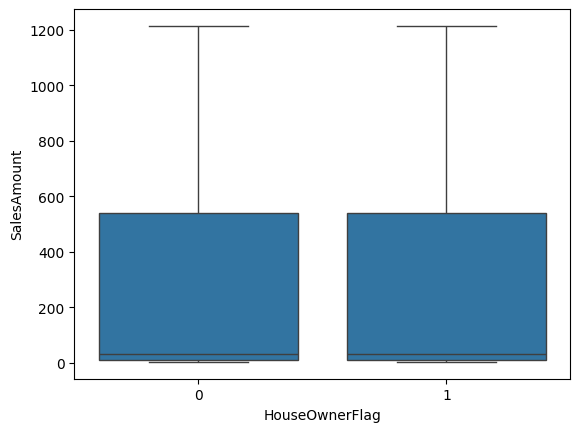

In [28]:
sns.boxplot(
    data=sales,
    x='HouseOwnerFlag',
    y='SalesAmount',
    showfliers=False
)

plt.show()

In [29]:
#A simple regression
from statsmodels.formula.api import ols
model = ols('SalesAmount ~ HouseOwnerFlag',data=sales).fit(
    cov_type='cluster',
    cov_kwds={'groups': sales['CustomerKey']}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            SalesAmount   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                    0.7728
Date:                Sun, 01 Nov 2026   Prob (F-statistic):              0.379
Time:                        01:09:37   Log-Likelihood:            -4.9843e+05
No. Observations:               60398   AIC:                         9.969e+05
Df Residuals:                   60396   BIC:                         9.969e+05
Df Model:                           1                                         
Covariance Type:              cluster                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        479.8827      8.383     57.

In [30]:
# Count distinct homeownership statuses for each customer.
home_status_counts = (sales.groupby('CustomerKey')['HouseOwnerFlag'].nunique())

# Count customers with more than one homeownership status.
print("Customers with inconsistent homeownership status:",(home_status_counts > 1).sum())

Customers with inconsistent homeownership status: 0


In [31]:
# Aggregate total spending and homeownership status by customer.
customer_spending = sales.groupby('CustomerKey').agg(
  TotalSales=('SalesAmount', 'sum'),
  HouseOwnerFlag=('HouseOwnerFlag' , 'first')
).reset_index()
customer_spending

,CustomerKey,TotalSales,HouseOwnerFlag
0,11000,8248.9900,1
1,11001,6383.8800,0
2,11002,8114.0400,1
3,11003,8139.2900,0
4,11004,8196.0100,1
...,...,...,...
18479,29479,2049.0982,1
18480,29480,2442.0300,1
18481,29481,3374.9900,0
18482,29482,2049.0982,1


In [32]:
# Summarize customer spending by homeownership status.
home_summary = (
    customer_spending.groupby('HouseOwnerFlag')
    .agg(
        CustomerCount=('CustomerKey', 'count'),
        TotalSales=('TotalSales', 'sum'),
        MeanSpending=('TotalSales', 'mean'),
        MedianSpending=('TotalSales', 'median'),
        SDSpending=('TotalSales', 'std')
    )
    .rename(index={0: 'Non-homeowners', 1: 'Homeowners'})
)

home_summary.index.name = 'Homeownership'

display(
    home_summary.style.format({
        'CustomerCount': '{:,.0f}',
        'TotalSales': '{:,.2f}',
        'MeanSpending': '{:,.2f}',
        'MedianSpending': '{:,.2f}',
        'SDSpending': '{:,.2f}'
    })
)

,CustomerCount,TotalSales,MeanSpending,MedianSpending,SDSpending
Homeownership,,,,,
Non-homeowners,"5,982","8,973,327.42","1,500.05",209.96,"2,046.88"
Homeowners,"12,502","20,385,349.80","1,630.57",342.00,"2,159.07"


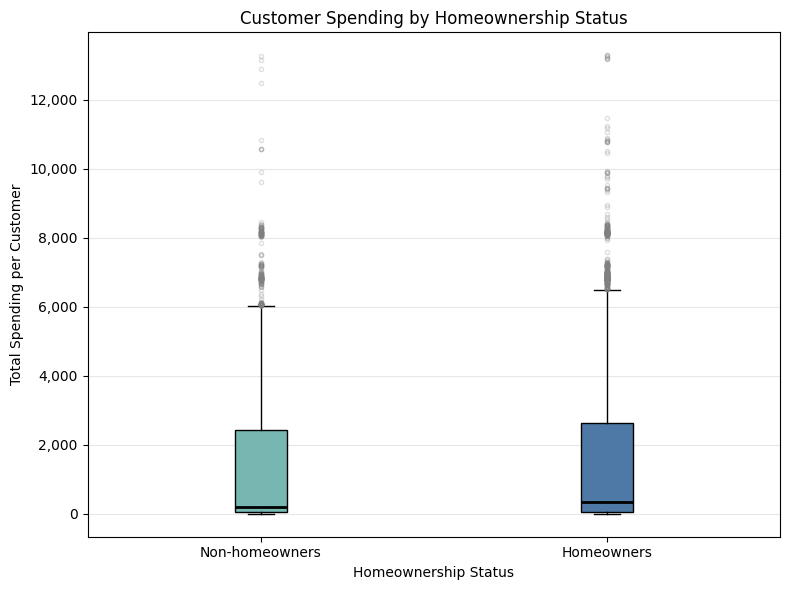

In [33]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Separate customer spending into the two homeownership groups.
non_homeowners = customer_spending.loc[customer_spending['HouseOwnerFlag'] == 0, 'TotalSales']
homeowners = customer_spending.loc[customer_spending['HouseOwnerFlag'] == 1, 'TotalSales']

# Compare the distributions of total spending per customer.
fig, ax = plt.subplots(figsize=(8, 6))
boxes = ax.boxplot([non_homeowners, homeowners],
    patch_artist=True,
    showfliers=True,
    medianprops={'color': 'black', 'linewidth': 2},
    flierprops={'marker': 'o','markersize': 3,'alpha': 0.25,'markeredgecolor': 'gray'})

for box, color in zip(boxes['boxes'], ['#76B7B2', '#4E79A7']):
    box.set_facecolor(color)

ax.set_xticks([1, 2])
ax.set_xticklabels(['Non-homeowners', 'Homeowners'])
ax.set_title('Customer Spending by Homeownership Status')
ax.set_xlabel('Homeownership Status')
ax.set_ylabel('Total Spending per Customer')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig('customer_spending_by_homeownership.png',dpi=300,bbox_inches='tight')
plt.show()

In [34]:
import statsmodels.formula.api as smf

# Verify that the additional customer attributes are consistent.
control_columns = ['YearlyIncome', 'BirthDate','EnglishCountryRegionName', 'MaritalStatus']
control_checks = (sales.groupby('CustomerKey')[control_columns].nunique(dropna=False))

assert not control_checks.gt(1).any().any(), ("Some customer attributes are inconsistent across records.")

# Create one row per customer and merge with customer spending.
customer_controls = sales[['CustomerKey'] + control_columns].drop_duplicates(subset='CustomerKey')

regression_data = customer_spending.merge(
    customer_controls,
    on='CustomerKey',
    how='left',
    validate='one_to_one'
)

# Calculate age at the end of the observation period.
regression_data['BirthDate'] = pd.to_datetime(regression_data['BirthDate'],errors='raise')
reference_date = sales['OrderDate'].max()
regression_data['Age'] = ((reference_date - regression_data['BirthDate']).dt.days / 365.25)

# Express income in units of 10,000 for easier interpretation.
regression_data['Income10k'] = (regression_data['YearlyIncome'] / 10_000)

# Check the variables used in the regression.
model_columns = ['TotalSales', 'HouseOwnerFlag', 'Income10k','Age', 'EnglishCountryRegionName', 'MaritalStatus']

display(regression_data[model_columns].isna().sum())
display(regression_data[['Age', 'Income10k']].describe())

,0
TotalSales,0
HouseOwnerFlag,0
Income10k,0
Age,0
EnglishCountryRegionName,0
MaritalStatus,0


,Age,Income10k
count,18484.000000,18484.000000
mean,44.750990,5.730578
std,11.523243,3.228584
min,27.594798,1.000000
25%,35.411362,3.000000
50%,42.546201,6.000000
75%,52.312115,7.000000
max,97.965777,17.000000


In [35]:
# Estimate the adjusted association between homeownership and spending.
model = smf.ols(formula=('TotalSales ~ HouseOwnerFlag + Income10k + Age + C(EnglishCountryRegionName) + C(MaritalStatus)'),
    data=regression_data,missing='raise').fit(cov_type='HC3')

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             TotalSales   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     152.9
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          2.94e-280
Time:                        01:09:38   Log-Likelihood:            -1.6697e+05
No. Observations:               18484   AIC:                         3.340e+05
Df Residuals:                   18474   BIC:                         3.340e+05
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------